In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score


In [4]:
# Step 1: Generate Clinical Benchmark Dataset
np.random.seed(42)
n_samples = 500

# Generate realistic clinical features
age = np.random.randint(29, 78, n_samples)
sex = np.random.randint(0, 2, n_samples)
cp = np.random.randint(0, 4, n_samples) # Chest Pain type
trestbps = np.random.randint(94, 200, n_samples) # Resting Blood Pressure
chol = np.random.randint(126, 564, n_samples) # Serum Cholesterol
fbs = np.random.randint(0, 2, n_samples) # Fasting Blood Sugar
thalach = np.random.randint(71, 202, n_samples) # Max Heart Rate
exang = np.random.randint(0, 2, n_samples) # Exercise Induced Angina

# Define disease target based on risk factors
risk_score = (age * 0.03) + (cp * 0.4) + (trestbps * 0.01) + (chol * 0.005) - (thalach * 0.02) + (exang * 0.5)
target = (risk_score > np.median(risk_score)).astype(int)

# Create DataFrame
df = pd.DataFrame({
    'age': age,
    'sex': sex,
    'chest_pain': cp,
    'blood_pressure': trestbps,
    'cholesterol': chol,
    'fasting_bs': fbs,
    'max_heart_rate': thalach,
    'exercise_angina': exang,
    'target': target
})

print("Clinical Medical Dataset Generated Successfully!")
print("Dataset Shape:", df.shape)

Clinical Medical Dataset Generated Successfully!
Dataset Shape: (500, 9)


In [5]:
# Step 2: Feature & Target Separation
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# Step 3: Model Training (Random Forest Classifier)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [7]:
# Step 4: Model Evaluation
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("\n--- DISEASE PREDICTION MODEL METRICS ---")
print(f"Accuracy : {acc * 100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred))


--- DISEASE PREDICTION MODEL METRICS ---
Accuracy : 89.00%
ROC-AUC  : 0.9716

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.94      0.90        50
           1       0.93      0.84      0.88        50

    accuracy                           0.89       100
   macro avg       0.89      0.89      0.89       100
weighted avg       0.89      0.89      0.89       100



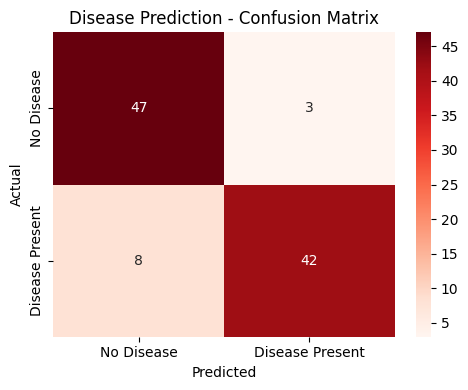

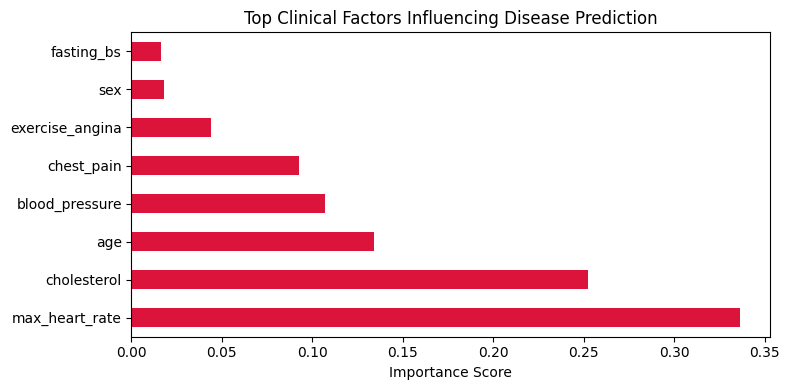

In [8]:
# Step 5: Visualizations
# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['No Disease', 'Disease Present'],
            yticklabels=['No Disease', 'Disease Present'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Disease Prediction - Confusion Matrix')
plt.tight_layout()
plt.show()

# 2. Key Clinical Feature Importance Plot
plt.figure(figsize=(8, 4))
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(8).plot(kind='barh', color='crimson')
plt.title('Top Clinical Factors Influencing Disease Prediction')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()